In [ ]:
# AI-use disclosure 
# The code in this repository (src/covidphylo, scripts/, notebooks/) was drafted with Claude (Anthropic).
# I ran it, checked the results against simulated ground truth and the unit tests (pytest),
# and am responsible for everything submitted.


# 00 - Exploratory analysis, QC and variant discovery (shared by Projects A and B)

Covers the presentation outline items *Dataset and its characteristics*, *Exploratory analysis* and
*Quality-control and evaluation metrics*, plus SNP calling and lineage-defining mutations.
`MODE = "sim"` runs anywhere; `MODE = "real"` needs `data/subsample/aligned.fasta` (see README section 3).

In [33]:
import sys, pathlib
ROOT = pathlib.Path.cwd().resolve()
if not (ROOT / "src").exists():            # allow running from notebooks/
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

In [34]:
MODE = "sim"
SEED = 1
OUT = ROOT / "results" / "eda_notebook"
OUT.mkdir(parents=True, exist_ok=True)
from covidphylo import eda, qc, variants
from covidphylo.seqio import Alignment

if MODE == "sim":
    from covidphylo.simulate import simulate_dataset
    sim = simulate_dataset(300, seed=SEED)
    aln, labels = sim.aln, sim.lineages
    meta = pd.DataFrame({"name": aln.names, "lineage": [labels[n] for n in aln.names],
                         "date": [f"{int(sim.tip_dates[n])}-{1 + int((sim.tip_dates[n] % 1) * 12):02d}-15" for n in aln.names]})
    ref, mask = variants.consensus(aln), qc.build_mask(aln.length)
else:
    aln = Alignment.from_fasta(ROOT / "data" / "subsample" / "aligned.fasta")
    i = aln.names.index("NC_045512.2")                      # reference row is part of the alignment
    ref = aln.X[i].copy(); aln = aln.subset([k for k in range(aln.n) if k != i])
    meta = qc.read_metadata(ROOT / "data" / "metadata.tsv")
    labels = dict(zip(meta["name"], meta["lineage"]))
    vcf = ROOT / "data" / "problematic_sites_sarsCov2.vcf"
    mask = qc.build_mask(aln.length, qc.read_problematic_sites_vcf(vcf) if vcf.exists() else None)
pd.Series(eda.eda_summary(aln, meta, mask))

n_sequences                 300.000000
alignment_length          29903.000000
n_variable_sites           2435.000000
variable_site_fraction        0.081430
median_ambig_fraction         0.000000
n_masked_sites              155.000000
n_lineages                   79.000000
n_complete_dates            300.000000
date_min                   2020.535519
date_max                   2022.038356
dtype: float64

## 1. Exploratory figure (lineages, dates, quality, variation along the genome, pairwise distances)

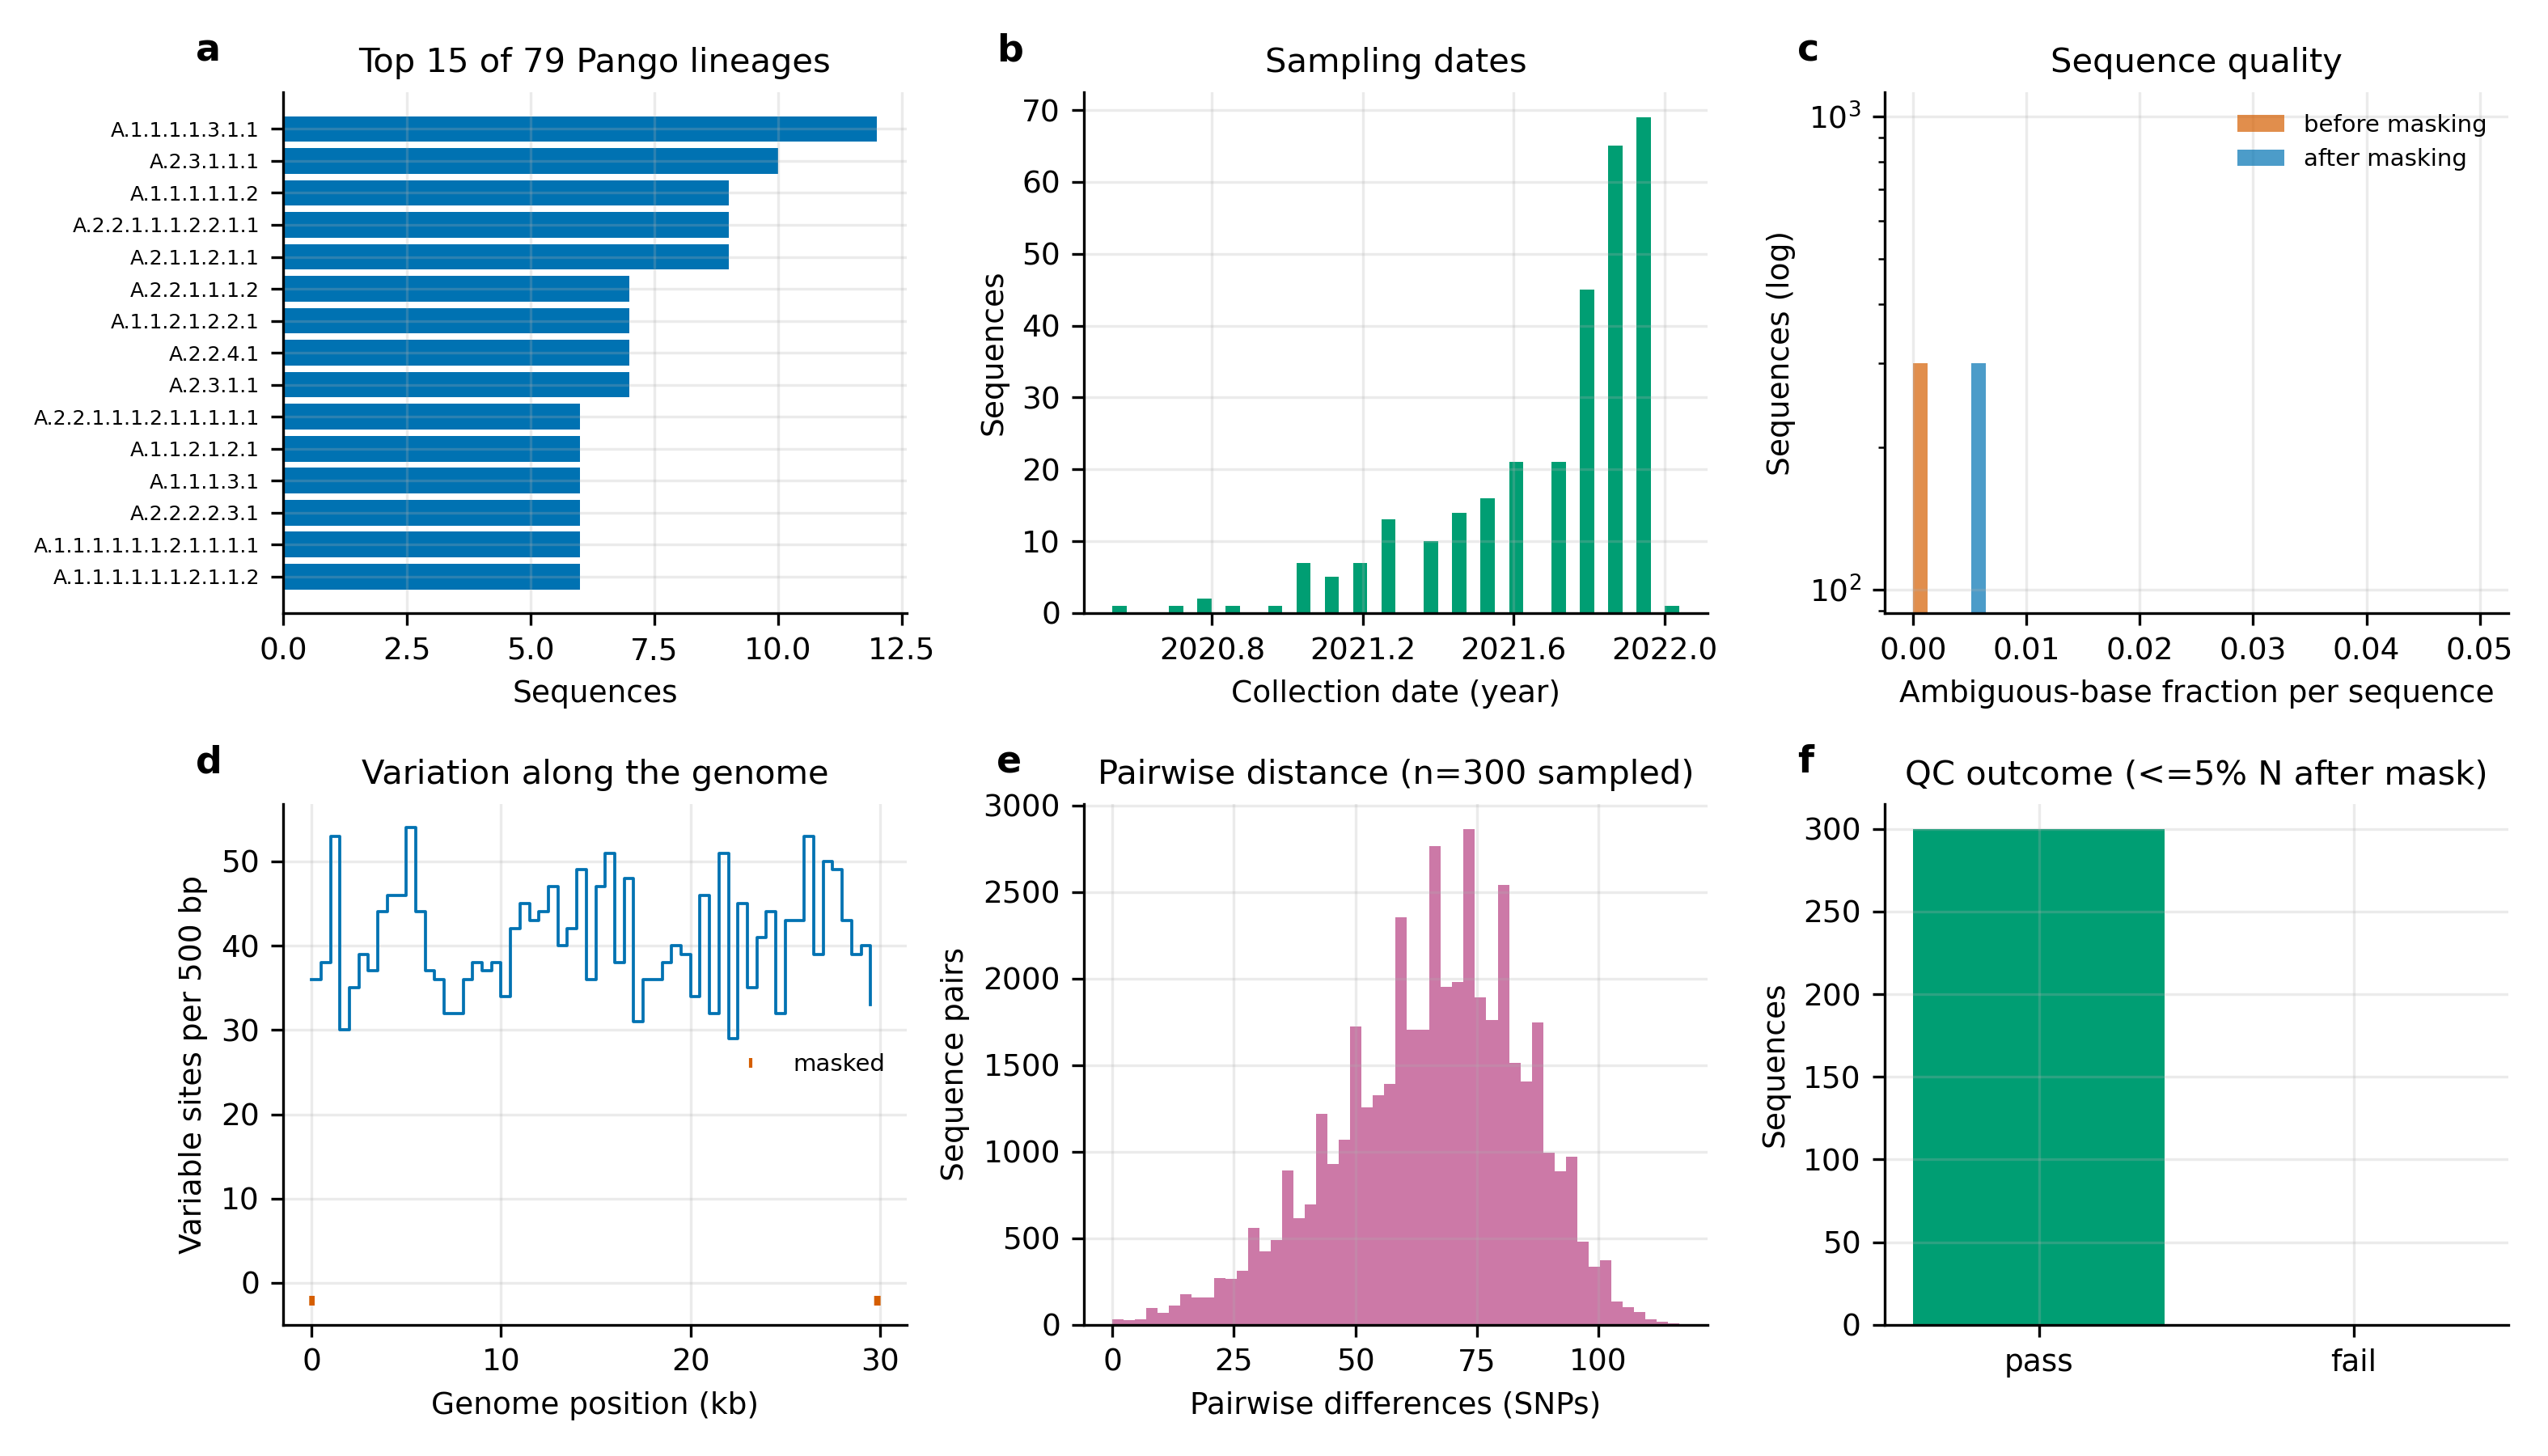

In [36]:
display(Image(str(eda.eda_panel(aln, meta, OUT, mask_sites=mask, seed=SEED))))

## 2. QC per sequence (ambiguous fraction after masking; threshold 5%)

In [38]:
q = eda.qc_table(aln, mask)
print(q["pass"].value_counts().to_dict())
q.sort_values("ambig_after_mask", ascending=False).head()

{True: 300}


,name,ambig_before_mask,ambig_after_mask,pass
0,seq00000,0.0,0.005183,True
206,seq00206,0.0,0.005183,True
204,seq00204,0.0,0.005183,True
203,seq00203,0.0,0.005183,True
202,seq00202,0.0,0.005183,True


## 3. Variant discovery: SNPs versus the reference

In [40]:
masked = aln.mask_sites(mask)
sites = variants.site_table(masked, ref)
calls = variants.call_snps(masked, ref)
per = variants.snps_per_sample(calls, masked)
print(f"{len(sites)} variable sites, {len(calls)} SNP calls, median {per.median():.0f} SNPs/genome vs reference")
sites.sort_values("alt_freq", ascending=False).head(10)

2421 variable sites, 11002 SNP calls, median 37 SNPs/genome vs reference


,pos,ref,alt,n_valid,n_alt,alt_freq,n_A,n_C,n_G,n_T
2033,25418,G,A,300,137,0.456667,137,0,163,0
378,4773,C,T,300,125,0.416667,0,175,0,125
661,8295,G,A,300,124,0.413333,124,0,175,1
1123,14026,A,G,300,121,0.403333,179,0,121,0
1890,23554,T,C,300,120,0.400000,0,120,0,180
988,12425,A,G,300,120,0.400000,180,0,120,0
1128,14049,G,A,300,120,0.400000,120,0,180,0
2293,28251,T,A,300,120,0.400000,120,0,0,180
2125,26361,C,T,300,120,0.400000,0,180,0,120
309,4018,A,T,300,119,0.396667,181,0,0,119


## 4. Lineage-defining mutations
Sites where a lineage (and its sub-lineages) carries a non-reference allele in >= 90% of genomes but <= 5% elsewhere.
Pango aliases are not resolved, so real-data results are conservative.

In [42]:
ld = variants.lineage_defining_sites(masked, ref, labels)
ld.to_csv(OUT / "lineage_defining_sites.csv", index=False)
print(ld["lineage"].nunique(), "lineages with defining sites")
ld.head(10)

79 lineages with defining sites


,lineage,pos,ref,alt,freq_in,freq_out,n_in
0,A.1,3050,A,G,0.950000,0.000000,120
1,A.1,4018,A,T,0.991667,0.000000,120
2,A.1,6022,A,G,0.925000,0.000000,120
3,A.1,8278,T,A,0.991667,0.000000,120
4,A.1,12425,A,G,1.000000,0.000000,120
5,A.1,14026,A,G,1.000000,0.005556,120
6,A.1,14049,G,A,1.000000,0.000000,120
7,A.1,15103,A,G,0.991667,0.005556,120
8,A.1,23554,T,C,1.000000,0.000000,120
9,A.1,26361,C,T,1.000000,0.000000,120
